# EDA — Docentes

## Índice
1. Importación y compatibilidad de columnas
2. Cobertura, categorías y claves candidatas
3. Tratamiento de `Sexo` y `Departamento`
4. Docentes y departamentos por año
5. Perfiles numéricos y controles completos de calidad
6. Metadatos: definiciones, ceros y límites
7. Exportación verificada y conclusiones

**Alcance:** diagnóstico de calidad de los registros descargados, 2019–2025. No representa un censo de todo el personal docente ni demuestra causalidad.

**Qué representa una fila:** la combinación docente × año × subsistema casi identifica los registros, con una excepción observada (ID 199850, 2024). Los metadatos 2019–2022 documentan actividad por persona y repetición entre subsistemas; los controles completos de abajo identifican excepciones. No sumar actividad entre filas de subsistemas.

## Importación de librería y datos

Se cargan los datos consolidados en Parquet (Etapa I) y se crea `df_d`. Las columnas de CREA de comentarios y acciones se unifican con `combine_first`, porque cambian de nombre entre archivos.

**Supuesto:** combinar nombres no prueba que la definición sea idéntica en 2025. La documentación local describe 2019–2022; la equivalencia de los años recientes queda pendiente para Ceibal.

**Nota de Transparencia sobre IA** La siguiente celda fue retocada con IA, la idea era experimentar con las librerías, constantes y funciones de control. En las primeras versiones de este notebook, esta celda era más simple y cumplía la función de usar Path para encontrar el archivo. Al terminar el EDA, volví sobre este documento y comencé a experimentar. Estas son algunas de las cosas que hace diferente a comparación de la celda original:

**Constantes**
- `ID`, `YEAR`, `DEPT`: nombres de las columnas `Id persona`, `Año lectivo` y `Departamento`.
- `KEY`: la combinación docente–año (`[ID, YEAR]`).
- `MISSING_TEXT`: textos que cuentan como faltantes ("Sin Dato", "Sin Datos" y texto vacío).

**Funciones**
- `raiz_proyecto()`: busca la carpeta que contiene `Recursos/` y `Datasets & Metadatos/`, para que el notebook funcione tanto si se abre Jupyter desde la raíz como desde esta carpeta.
- `sha256()`: calcula la huella de un archivo, para comprobar que el original no cambió.
- `perfil_columnas()`: por columna, el tipo, los nulos, los valores distintos y los "Sin Dato" escritos como texto.
- `perfil_numerico()`: describe las columnas numéricas con percentiles, ceros, negativos, valores no finitos y no enteros.
- `control_dias()`: cuenta filas cuyos días superan los días del año.
- `resumen_anual()`: filas y personas distintas por año.
- `control_repeticiones()`: prueba claves candidatas y busca grupos docente–año repetidos con valores distintos.
- `disponibilidad()`: por año y subsistema, cuántas filas de cada métrica son nulas, cero, positivas o negativas.
- `faltantes_por_grupo()`: cuenta faltantes (nulos o "Sin Dato") por grupo.
- `exportar_verificado()`: guarda el Parquet limpio, lo vuelve a leer, comprueba que es idéntico y escribe un manifest con huellas y versiones.

In [1]:

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Funciones de control del EDA (antes en utilidades_eda.py, ahora dentro del notebook).
# Describen registros: no imputan, eliminan ni agregan filas.
import calendar
import hashlib
import json
import platform
import pyarrow

ID = "Id persona"
YEAR = "Año lectivo"
DEPT = "Departamento"
KEY = [ID, YEAR]
MISSING_TEXT = {"Sin Dato", "Sin Datos", ""}


def raiz_proyecto():
    """Permite iniciar Jupyter desde la raíz o desde la carpeta del notebook."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "Recursos").is_dir() and (folder / "Datasets & Metadatos").is_dir():
            return folder
    raise FileNotFoundError("No se encontró la raíz del proyecto Ceibal")


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def perfil_columnas(df):
    rows = []
    for col in df:
        series = df[col]
        textual = pd.api.types.is_object_dtype(series) or isinstance(series.dtype, pd.StringDtype)
        rows.append({
            "columna": col, "tipo": str(series.dtype), "filas": len(df),
            "nulos": int(series.isna().sum()), "nulos_pct": series.isna().mean() * 100,
            "valores_distintos_conocidos": series.nunique(),
            "sin_dato_textual": int(series.isin(MISSING_TEXT).sum()) if textual else 0,
            "sin_clasificar": int(series.eq("Sin clasificar").sum()) if textual else 0,
        })
    return pd.DataFrame(rows).set_index("columna")


def perfil_numerico(df, metrics):
    """Percentiles sobre todas las filas, con denominador no nulo explícito."""
    result = df[metrics].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).T
    result["nulos"] = df[metrics].isna().sum()
    result["ceros"] = df[metrics].eq(0).sum()
    result["ceros_pct_no_nulos"] = result["ceros"].div(result["count"].replace(0, np.nan)) * 100
    result["negativos"] = df[metrics].lt(0).sum()
    result["no_finitos_no_nulos"] = [int((~np.isfinite(df[c]) & df[c].notna()).sum()) for c in metrics]
    result["no_enteros_no_nulos"] = [int((df[c].mod(1).ne(0) & df[c].notna()).sum()) for c in metrics]
    return result


def control_dias(df, metrics):
    max_days = df[YEAR].map(lambda year: 366 if calendar.isleap(int(year)) else 365)
    return pd.DataFrame([
        {"columna": col, "filas_superan_dias_del_anio": int(df[col].gt(max_days).sum())}
        for col in metrics if col.startswith("Cantidad de días")
    ]).set_index("columna")


def resumen_anual(df):
    grouped = df.groupby(YEAR)
    result = grouped.size().to_frame("filas")
    result["personas_distintas"] = grouped[ID].nunique()
    result["filas_extra_por_persona_anio"] = result["filas"] - result["personas_distintas"]
    assert result["filas"].sum() == len(df)
    return result


def control_repeticiones(df, metrics):
    """Inspecciona TODOS los pares repetidos, incluidas diferencias nulo/valor."""
    duplicate_mask = df.duplicated(KEY, keep=False)
    repeated = df.loc[duplicate_mask, KEY + metrics]
    variation = repeated.groupby(KEY)[metrics].nunique(dropna=False)
    summary = pd.DataFrame({
        "grupos_repetidos": len(variation),
        "grupos_con_valores_distintos": variation.gt(1).sum(),
    })
    conflicts = variation.loc[variation.gt(1).any(axis=1)]
    keys = pd.DataFrame([
        {"clave_candidata": " + ".join(cols), "filas_extra": int(df.duplicated(cols).sum()),
         "filas_en_grupos_repetidos": int(df.duplicated(cols, keep=False).sum())}
        for cols in [KEY, KEY + ["Subsistema"]]
    ])
    return keys, summary, conflicts


def disponibilidad(df, metrics):
    """Cada fila cuenta como exactamente un estado: nulo/cero/positivo/negativo."""
    parts = []
    for col in metrics:
        states = pd.DataFrame({
            YEAR: df[YEAR], "Subsistema": df["Subsistema"],
            "filas": 1, "nulos": df[col].isna(), "ceros": df[col].eq(0),
            "positivos": df[col].gt(0), "negativos": df[col].lt(0),
        })
        grouped = states.groupby([YEAR, "Subsistema"]).sum()
        assert grouped[["nulos", "ceros", "positivos", "negativos"]].sum(axis=1).eq(grouped["filas"]).all()
        grouped["nulos_pct"] = grouped["nulos"].div(grouped["filas"]) * 100
        grouped["metrica"] = col
        parts.append(grouped.reset_index())
    return pd.concat(parts, ignore_index=True)


def faltantes_por_grupo(df, dimensions, group_columns):
    parts = []
    for col in dimensions:
        result = df.groupby(group_columns).size().to_frame("filas")
        mask = df[col].isna() | df[col].isin(MISSING_TEXT)
        counts = df.loc[mask].groupby(group_columns).size()
        result["faltantes"] = counts.reindex(result.index, fill_value=0)
        result["faltantes_pct"] = result["faltantes"].div(result["filas"]) * 100
        result["columna"] = col
        parts.append(result.reset_index())
    return pd.concat(parts, ignore_index=True)


def exportar_verificado(df, path, source, population, transformations):
    """Escribe la copia limpia y comprueba igualdad completa tras releerla."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(path, index=False, engine="pyarrow")
    reread = pd.read_parquet(path)
    pd.testing.assert_frame_equal(df.reset_index(drop=True), reread, check_dtype=True)
    manifest = {
        "fecha_cierre": "2026-10-20", "autor_cierre": "yo",
        "poblacion": population, "filas": len(df), "columnas": len(df.columns),
        "personas_distintas": int(df[ID].nunique()),
        "tipos": df.dtypes.astype(str).to_dict(),
        "nulos": {c: int(n) for c, n in df.isna().sum().items()},
        "transformaciones": transformations,
        "origen_relativo": str(Path(source).relative_to(raiz_proyecto())),
        "origen_sha256": sha256(source), "salida_sha256": sha256(path),
        "relectura_identica": True,
        "versiones": {"python": platform.python_version(), "pandas": pd.__version__, "pyarrow": pyarrow.__version__},
    }
    path.with_suffix(".manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    return manifest


RAIZ = raiz_proyecto()
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.max_colwidth", 105)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
ruta_docentes = RAIZ / "Recursos/Dataset docentes concatenado/dataset_docentes_consolidado.parquet"
huella_docentes_antes = sha256(ruta_docentes)
df_d = pd.read_parquet(ruta_docentes)
filas_docentes_originales = len(df_d)
ids_docentes_originales = df_d[ID].nunique()
print(f"Origen: {len(df_d):,} filas; {df_d[ID].nunique():,} IDs distintos; {df_d.shape[1]} columnas")

Origen: 379,153 filas; 74,929 IDs distintos; 14 columnas


In [3]:
# Los dos nombres ocupan años diferentes; comprobarlo antes de combinar.
compatibilidad = []
for nombre, anterior in [("comentarios", "Cantidad de Comentarios posteados"),
                         ("acciones", "Cantidad de Acciones totales")]:
    reciente = anterior + " en CREA"
    solapadas = df_d[anterior].notna() & df_d[reciente].notna()
    compatibilidad.append({"metrica": nombre, "ambas_versiones_con_valor": int(solapadas.sum()),
                          "ambas_sin_valor": int((df_d[anterior].isna() & df_d[reciente].isna()).sum())})
    assert not solapadas.any(), "Revisar precedencia: ambas versiones tienen valor"
    df_d[nombre] = df_d[anterior].combine_first(df_d[reciente])
    assert df_d[nombre].notna().all()
    df_d = df_d.drop(columns=[anterior, reciente])
display(pd.DataFrame(compatibilidad))

,metrica,ambas_versiones_con_valor,ambas_sin_valor
0,comentarios,0,0
1,acciones,0,0


### **Comprobación de los años que contiene cada archivo**

**Motivo.** Al revisar el catálogo de datos abiertos de Ceibal encontré dos inconsistencias de documentación en el dataset de estudiantes. Comprobé si el contenido de cada archivo coincide con el año que indica su nombre.

**Observaciones en la ficha del catálogo** (consultada el 12/10/2026):
1. La descripción del recurso "Actividad de estudiantes - 2024" dice "Corresponden a los datos de actividad del estudiante del año 2022", aunque su título y el nombre del archivo indican 2024. https://catalogodatos.gub.uy/dataset/centro_ceibal-actividad-en-plataformas-educativas-estudiantes/resource/b156c9bd-40dc-4b15-a952-bac8625ad6b3
2. El recurso "Actividad de estudiantes - 2023" se descarga como `estudiantes_datos_abiertos_agesic.csv`, sin año en el nombre y fuera de la nomenclatura de los demás archivos. https://catalogodatos.gub.uy/dataset/centro_ceibal-actividad-en-plataformas-educativas-estudiantes/resource/4d9ab478-cd34-4cbb-bbaa-61144e74dde1

**Comprobación en los datos.** Agrupé por `archivo_origen` y listé los valores de `Año lectivo`.

**Resultado.** Cada archivo, de estudiantes y de docentes, contiene un único año, igual al de su nombre. El archivo de 2024 contiene solo 2024 y el de 2023, solo 2023.

**Conclusión.** El contenido de los archivos es coherente con el año de su nombre; las inconsistencias están en la documentación del catálogo. Se desconoce la causa (por ejemplo, un error de redacción en la ficha): queda como consulta pendiente para Ceibal.

In [4]:
# Comprobación de archivos - Docentes
df_d.groupby("archivo_origen")["Año lectivo"].unique()

archivo_origen
actividad-de-docentes-2024.csv        [2024]
actividad-de-docentes-2025.csv        [2025]
datos_docentes_2019.csv               [2019]
datos_docentes_2020.csv               [2020]
datos_docentes_2021.csv               [2021]
datos_docentes_2022.csv               [2022]
docentes_datos_abiertos_agesic.csv    [2023]
Name: Año lectivo, dtype: object

## Exploración de los datos - DataFrame Docente

### Primeras aproximaciones

In [5]:
# Listado de columnas en el DF de docentes (df_d)
for i, col in enumerate(df_d.columns, start=1):
    print(f"{i}. {col}")

1. Id persona
2. Sexo
3. Rol
4. Departamento
5. Subsistema
6. Año lectivo
7. Cantidad de días ingreso a CREA
8. Cantidad de días de ingreso a Biblioteca
9. Cantidad de préstamos en biblioteca
10. archivo_origen
11. comentarios
12. acciones


In [6]:
df_d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 379153 entries, 0 to 379152
Data columns (total 12 columns):
 #   Column                                    Non-Null Count   Dtype  
---  ------                                    --------------   -----  
 0   Id persona                                379153 non-null  string 
 1   Sexo                                      379153 non-null  object 
 2   Rol                                       379153 non-null  object 
 3   Departamento                              379153 non-null  object 
 4   Subsistema                                379153 non-null  object 
 5   Año lectivo                               379153 non-null  int64  
 6   Cantidad de días ingreso a CREA           379153 non-null  int64  
 7   Cantidad de días de ingreso a Biblioteca  379153 non-null  int64  
 8   Cantidad de préstamos en biblioteca       379153 non-null  int64  
 9   archivo_origen                            379153 non-null  object 
 10  comentarios         

In [7]:
df_d["Sexo"].value_counts()

Sexo
Femenino      243968
Masculino      78631
Femenino       42469
Masculino      13605
Sin Dato         480
Name: count, dtype: int64

In [8]:
df_d.head()

,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
0,702122,Femenino,Docente,Montevideo,DGES,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0
1,199850,Masculino,Docente,Montevideo,DGETP,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0
2,1686169,Masculino,Docente,Salto,DGES,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0
3,1680863,Masculino,Docente,Montevideo,DGEIP,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0
4,1802728,Femenino,Docente,Paysandu,DGES,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0


### Normalización de categorías y revisión de repeticiones

Se quitan espacios exteriores; no se eliminan filas repetidas.

Se revisa cada columna de texto por archivo de origen. `repr` deja a la vista los espacios de relleno que no se ven en pantalla.

In [9]:
pd.crosstab(df_d["archivo_origen"], df_d["Sexo"].map(repr))

Sexo,'Femenino ','Femenino','Masculino ','Masculino','Sin Dato'
archivo_origen,,,,,
actividad-de-docentes-2024.csv,0,41822,0,13342,1
actividad-de-docentes-2025.csv,42469,0,13605,0,0
datos_docentes_2019.csv,0,38806,0,12112,452
datos_docentes_2020.csv,0,38053,0,12066,3
datos_docentes_2021.csv,0,39787,0,12606,0
datos_docentes_2022.csv,0,41294,0,13188,13
docentes_datos_abiertos_agesic.csv,0,44206,0,15317,11


In [10]:
# Tenemos que limpiar los strings de la columna "Sexo"
# Al escribir el dataset probablemente hubo un error de exportación y de esa manera aparece (" ") al final de la palabra
# Para Python, estos son dos cosas distintas. Así que debemos limpiarlas

df_d["Sexo"] = df_d["Sexo"].str.strip()
df_d["Sexo"].value_counts()

Sexo
Femenino     286437
Masculino     92236
Sin Dato        480
Name: count, dtype: int64

In [11]:
pd.crosstab(df_d["archivo_origen"], df_d["Subsistema"].map(repr))

Subsistema,'DGEIP ','DGEIP','DGES ','DGES','DGETP ','DGETP'
archivo_origen,,,,,,
actividad-de-docentes-2024.csv,0,20203,0,20931,0,14031
actividad-de-docentes-2025.csv,20380,0,21180,0,14514,0
datos_docentes_2019.csv,0,18968,0,20239,0,12163
datos_docentes_2020.csv,0,18050,0,19644,0,12428
datos_docentes_2021.csv,0,20002,0,19561,0,12830
datos_docentes_2022.csv,0,20125,0,21205,0,13165
docentes_datos_abiertos_agesic.csv,0,19954,0,26214,0,13366


In [12]:
# Al igual que antes, debemos limpiar los espacios en blanco de la columna "Subsistema"

df_d["Subsistema"] = df_d["Subsistema"].str.strip()
df_d["Subsistema"].value_counts()

Subsistema
DGES     148974
DGEIP    137682
DGETP     92497
Name: count, dtype: int64

In [13]:
pd.crosstab(df_d["archivo_origen"], df_d["Departamento"].map(repr))

Departamento,'Artigas ','Artigas','Canelones ','Canelones','Cerro Largo ','Cerro Largo','Colonia ','Colonia',...,'Sin Dato ','Sin Dato','Soriano ','Soriano','Tacuarembo ','Tacuarembo','Treinta Y Tres ','Treinta Y Tres'
archivo_origen,,,,,,,,,,,,,,,,,
actividad-de-docentes-2024.csv,0,1706,0,8966,0,1886,0,2554,...,0,31,0,1659,0,1962,0,1016
actividad-de-docentes-2025.csv,1801,0,9271,0,1853,0,2583,0,...,8,0,1679,0,1946,0,1031,0
datos_docentes_2019.csv,0,1614,0,8109,0,1736,0,2387,...,0,0,0,1747,0,1948,0,1049
datos_docentes_2020.csv,0,1570,0,8096,0,1717,0,2325,...,0,0,0,1663,0,1854,0,964
datos_docentes_2021.csv,0,1637,0,8482,0,1819,0,2438,...,0,0,0,1678,0,1939,0,983
datos_docentes_2022.csv,0,1684,0,9132,0,1782,0,2520,...,0,0,0,1690,0,1906,0,1008
docentes_datos_abiertos_agesic.csv,0,1963,0,9544,0,1842,0,2999,...,0,0,0,2019,0,2058,0,1118


In [14]:
# Al igual que antes, debemos limpiar los espacios en blanco de la columna "Departamento"

df_d["Departamento"] = df_d["Departamento"].str.strip()
df_d["Departamento"].value_counts()

Departamento
Montevideo        109581
Canelones          61600
Maldonado          20495
Salto              17980
Colonia            17806
Rivera             16286
Paysandu           16201
San Jose           13800
Tacuarembo         13613
Cerro Largo        12635
Soriano            12135
Artigas            11975
Rocha              10524
Florida             9781
Rio Negro           8279
Durazno             8230
Lavalleja           7536
Treinta Y Tres      7169
Flores              3488
Sin Dato              39
Name: count, dtype: int64

**Repeticiones por docente y año.** Se prueban claves candidatas y se inspeccionan diferencias; una repetición no se interpreta automáticamente como un error ni se elimina.

In [15]:
# Vamos a ver la cantidad de ID's duplicados
# Hay que tener en cuenta que se repiten, a veces, porque son ID de docentes 
# que pueden estar en distintos subsistemas en un mismo año.
df_d["Id persona"].nunique(), len(df_d)

(74929, 379153)

In [16]:
df_d.duplicated(subset=["Id persona", "Año lectivo"]).sum()

np.int64(39031)

In [17]:
df_d["Id persona"].value_counts().value_counts().sort_index()

count
1     16041
2      6022
3      5320
4      5341
5      4929
6      4947
7     24093
8      2027
9       991
10      820
11      649
12      690
13      837
14     2211
15        6
16        2
17        1
18        1
20        1
Name: count, dtype: Int64

In [18]:
dup = df_d[df_d.duplicated(subset=["Id persona", "Año lectivo"], keep=False)] # Variable para verificar duplicados por "id" y "año lectivo"

# Vamos a ver un ejemplo de un id repetido
id_ejemplo = dup["Id persona"].iloc[0]
df_d[df_d["Id persona"] == id_ejemplo].sort_values("Año lectivo")

,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
120798,199850,Masculino,Docente,Montevideo,DGETP,2019,106,0,0,datos_docentes_2019.csv,10.0,825.0
171560,199850,Masculino,Docente,Montevideo,DGETP,2020,92,0,0,datos_docentes_2020.csv,11.0,959.0
222385,199850,Masculino,Docente,Montevideo,DGETP,2021,55,1,0,datos_docentes_2021.csv,13.0,175.0
329948,199850,Masculino,Docente,Montevideo,DGETP,2023,33,1,1,docentes_datos_abiertos_agesic.csv,8.0,138.0
329949,199850,Masculino,Docente,Montevideo,DGES,2023,33,1,1,docentes_datos_abiertos_agesic.csv,8.0,138.0
1,199850,Masculino,Docente,Montevideo,DGETP,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0
2284,199850,Masculino,Docente,Montevideo,DGETP,2024,136,2,0,actividad-de-docentes-2024.csv,24.0,1478.0


In [19]:
dup["archivo_origen"].value_counts()

archivo_origen
docentes_datos_abiertos_agesic.csv    12607
actividad-de-docentes-2024.csv        12268
actividad-de-docentes-2025.csv        12262
datos_docentes_2022.csv               10905
datos_docentes_2021.csv               10386
datos_docentes_2020.csv                9928
datos_docentes_2019.csv                9610
Name: count, dtype: int64

In [20]:
variacion = dup.groupby(["Id persona", "Año lectivo"])[["Sexo", "Departamento", "Subsistema", "acciones"]].nunique()

In [21]:
variacion.head()

Sexo  Departamento  Subsistema  acciones
Id persona Año lectivo                                          
1000117    2023            1             2           2         1
           2024            1             1           2         1
           2025            1             2           2         1
10044      2023            1             1           2         1
           2024            1             1           2         1

In [22]:
(variacion > 1).sum()

Sexo                0
Departamento     4420
Subsistema      38934
acciones            1
dtype: int64

In [23]:
v_raros = variacion[(variacion["Subsistema"] == 1) | (variacion["acciones"] > 1)]
v_raros

,,Sexo,Departamento,Subsistema,acciones
Id persona,Año lectivo,,,,
199850,2024,1,1,1,2


In [24]:
df_d.duplicated(subset=["Id persona", "Año lectivo", "Subsistema"]).sum()

np.int64(1)

**Aclaración de nueva hipótesis**

A partir de lo anterior, podemos concluir de que la hipótesis "una fila por docente y año" no es cierta, pues 
nos dió 39.031 repeticiones. Por ende, descartamos esta idea.

Sin embargo, la idea de "cada fila es un docente, en un año, en un subsistema" resistió a la prueba anterior.
Solamente ocurrió una repetición entre los años 2019 al 2025, por lo que momentáneamente es la mejor hipótesis que tenemos.

In [25]:
df_d[df_d.duplicated(subset=["Id persona", "Año lectivo", "Subsistema"], keep=False)]

,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
1,199850,Masculino,Docente,Montevideo,DGETP,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0
2284,199850,Masculino,Docente,Montevideo,DGETP,2024,136,2,0,actividad-de-docentes-2024.csv,24.0,1478.0


In [26]:
nulos_docentes = df_d.isna()

print(f"La cantidad de nulos por columna es:\n{nulos_docentes.sum()}\n ---------")
print(f"La proporción (%) de nulos por columna es de: \n{nulos_docentes.mean() * 100}\n ----------")

La cantidad de nulos por columna es:
Id persona                                  0
Sexo                                        0
Rol                                         0
Departamento                                0
Subsistema                                  0
Año lectivo                                 0
Cantidad de días ingreso a CREA             0
Cantidad de días de ingreso a Biblioteca    0
Cantidad de préstamos en biblioteca         0
archivo_origen                              0
comentarios                                 0
acciones                                    0
dtype: int64
 ---------
La proporción (%) de nulos por columna es de: 
Id persona                                  0.0
Sexo                                        0.0
Rol                                         0.0
Departamento                                0.0
Subsistema                                  0.0
Año lectivo                                 0.0
Cantidad de días ingreso a CREA             0.0
Cant

**Aclaración sobre los valores nulos**

En este caso, hay que tener mucho cuidado, el código anterior con .isna() arrojó de que no hay valores faltantes **codificados como NaN, así que si los faltantes están codificados como strings "Sin dato" o "Valor faltante" no serán contabilizados**. Dicho esto, se procederá a verificar cuántos valores "Sin dato" existen por cada columna.

In [27]:
for col in df_d.columns:
    cantidad = (df_d[col] == "Sin Dato").sum()
    print(col, cantidad)

Id persona 0
Sexo 480
Rol 0
Departamento 39
Subsistema 0
Año lectivo 0
Cantidad de días ingreso a CREA 0
Cantidad de días de ingreso a Biblioteca 0
Cantidad de préstamos en biblioteca 0
archivo_origen 0
comentarios 0
acciones 0


In [28]:
df_d.nunique()

Id persona                                  74929
Sexo                                            3
Rol                                             1
Departamento                                   20
Subsistema                                      3
Año lectivo                                     7
Cantidad de días ingreso a CREA               327
Cantidad de días de ingreso a Biblioteca      223
Cantidad de préstamos en biblioteca           141
archivo_origen                                  7
comentarios                                  2362
acciones                                     7551
dtype: int64

In [29]:
verificar_columnas = ["Sexo", "Rol", "Departamento", "Subsistema", "Año lectivo", "archivo_origen"]

for ncol in verificar_columnas:
    ncantidad = df_d[ncol].value_counts(dropna=False)
    print(f"\n{ncantidad}\n ---------")


Sexo
Femenino     286437
Masculino     92236
Sin Dato        480
Name: count, dtype: int64
 ---------

Rol
Docente    379153
Name: count, dtype: int64
 ---------

Departamento
Montevideo        109581
Canelones          61600
Maldonado          20495
Salto              17980
Colonia            17806
Rivera             16286
Paysandu           16201
San Jose           13800
Tacuarembo         13613
Cerro Largo        12635
Soriano            12135
Artigas            11975
Rocha              10524
Florida             9781
Rio Negro           8279
Durazno             8230
Lavalleja           7536
Treinta Y Tres      7169
Flores              3488
Sin Dato              39
Name: count, dtype: int64
 ---------

Subsistema
DGES     148974
DGEIP    137682
DGETP     92497
Name: count, dtype: int64
 ---------

Año lectivo
2023    59534
2025    56074
2024    55165
2022    54495
2021    52393
2019    51370
2020    50122
Name: count, dtype: int64
 ---------

archivo_origen
docentes_datos_abiertos_a

### Verificación de la columna `Sexo`

Verificaremos esta columna, la cual tiene 480 "Sin Dato"

In [30]:
df_sin_sexo = df_d[df_d["Sexo"] == "Sin Dato"].copy()
df_sin_sexo.head(480)

,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
54607,2078074,Sin Dato,Docente,Canelones,DGES,2024,13,0,0,actividad-de-docentes-2024.csv,8.0,58.0
111547,18772,Sin Dato,Docente,Colonia,DGES,2019,80,0,0,datos_docentes_2019.csv,24.0,222.0
112665,25732,Sin Dato,Docente,Paysandu,DGES,2019,1,0,0,datos_docentes_2019.csv,0.0,4.0
114515,78758,Sin Dato,Docente,Tacuarembo,DGES,2019,0,0,0,datos_docentes_2019.csv,0.0,0.0
118019,192944,Sin Dato,Docente,Colonia,DGES,2019,0,0,0,datos_docentes_2019.csv,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
374910,1136520,Sin Dato,Docente,Rocha,DGES,2023,4,1,0,docentes_datos_abiertos_agesic.csv,0.0,6.0
377114,1394511,Sin Dato,Docente,Soriano,DGES,2023,49,0,0,docentes_datos_abiertos_agesic.csv,0.0,103.0
379062,2032575,Sin Dato,Docente,Salto,DGES,2023,0,0,0,docentes_datos_abiertos_agesic.csv,0.0,0.0
379063,2032575,Sin Dato,Docente,Salto,DGETP,2023,0,0,0,docentes_datos_abiertos_agesic.csv,0.0,0.0


### Tratamiento de los "Sin Dato" en `Sexo`

**Observación**
- `isna()` da 0 nulos, pero `Sexo` tiene 480 filas con el texto "Sin Dato" (0,13% de las 379.153 filas).
- Esas filas corresponden a 465 docentes. De ellos, 62 tienen el sexo registrado en otras filas y 403 no lo tienen en ninguna.

**Decisión**
1. Para los 62 docentes con sexo conocido en otras filas: se completó `Sexo` con ese valor en 67 filas. Antes se verificó que cada uno de esos 62 docentes tiene un único sexo entre sus filas conocidas.
2. Para los 403 docentes sin sexo conocido en ninguna fila (413 filas): se conservan con "Sin Dato" como categoría y se excluyen solo en los análisis que usen `Sexo`.
3. No se imputa con proporción 50/50 ni con la proporción observada.

**Justificación**
- Completar desde otras filas del mismo docente no inventa información: usa un dato registrado para esa misma persona.
- Imputar con una proporción inventaría un dato que el origen no registra. Además, supondría que los faltantes se reparten igual que los datos conocidos, algo que no verificamos (ver hipótesis pendientes).
- Borrar las filas habría eliminado 403 docentes del dataset (74.929 → 74.526) y descartado información válida de otras columnas (departamento, subsistema, uso de plataformas) en análisis que no dependen del sexo.
- Mantener "Sin Dato" permite medir cuánto afecta el faltante a cada análisis.

**Efecto comprobado**
- Filas "Sin Dato" en `Sexo`: 480 → 413.
- Docentes con "Sin Dato": 465 → 403.
- Filas totales: 379.153 (sin cambio). Docentes totales: 74.929 (sin cambio).
- Nulos en `Sexo`: 0.

**Limitación**
- Todo análisis por sexo cubrirá 74.526 docentes, no los 74.929 del dataset.

**Hipótesis pendientes (sin verificar)**
- Los docentes con "Sin Dato" aparecen pocas veces (1,4 filas contra 5 de promedio). No sabemos si es por ingreso reciente, por un problema de registro u otra causa.
- Los faltantes podrían concentrarse en ciertos departamentos o subsistemas, y no estar repartidos como los datos conocidos. Se puede comprobar con una tabla de `Departamento` y `Subsistema` para los 403 docentes frente al resto.
- Un docente (ID 530768) figura con "Femenino" en seis años y con "Sin Dato" solo en 2023. Podría ser un problema de registro de un año, pero con un solo caso no se puede afirmar. Se puede consultar a Ceibal.

In [31]:
ids_sin_sexo = df_sin_sexo["Id persona"].unique()
mask = df_d["Id persona"].isin(ids_sin_sexo)
filas_de_esos = df_d[mask].copy()
filas_de_esos["Sexo"].value_counts()

Sexo
Sin Dato     480
Femenino     122
Masculino     62
Name: count, dtype: int64

In [32]:
conocido = filas_de_esos[filas_de_esos["Sexo"] != "Sin Dato"]
conocido["Id persona"].nunique()

62

In [33]:
docentes_antes = df_d["Id persona"].nunique()

df_sin_borrar = df_d[df_d["Sexo"] != "Sin Dato"]
docentes_despues = df_sin_borrar["Id persona"].nunique()

print(docentes_antes, docentes_despues, docentes_antes - docentes_despues)

74929 74526 403


In [34]:
consistencia = conocido.groupby("Id persona")["Sexo"].nunique()
consistencia.value_counts()

Sexo
1    62
Name: count, dtype: int64

In [35]:
# Ahora vamos a crear una tabla de consulta para ver dichas 62 docentes.
# No es necesario hacerlo, pero metodológicamente me parece correcto.

una_por_docente = conocido.drop_duplicates("Id persona")
tabla_docentes = una_por_docente.set_index("Id persona")["Sexo"]
len(tabla_docentes)

62

In [36]:
df_limpio = df_d.copy()
mascara = (df_limpio["Sexo"] == "Sin Dato") & (df_limpio["Id persona"].isin(tabla_docentes.index))
mascara.sum()

np.int64(67)

In [37]:
id_ejemplo = tabla_docentes.index[0]
df_d[df_d["Id persona"] == id_ejemplo][["Id persona", "Año lectivo", "Subsistema", "Sexo"]]

,Id persona,Año lectivo,Subsistema,Sexo
290,530768,2024,DGETP,Femenino
55394,530768,2025,DGETP,Femenino
130137,530768,2019,DGES,Femenino
130138,530768,2019,DGETP,Femenino
180639,530768,2020,DGETP,Femenino
180640,530768,2020,DGES,Femenino
231686,530768,2021,DGES,Femenino
231687,530768,2021,DGETP,Femenino
284973,530768,2022,DGES,Femenino
284974,530768,2022,DGETP,Femenino


In [38]:
es_sin_dato = df_limpio["Sexo"] == "Sin Dato"
esta_en_tabla = df_limpio["Id persona"].isin(tabla_docentes.index)
mascara = es_sin_dato & esta_en_tabla
mascara.sum()

np.int64(67)

In [39]:
df_limpio.loc[mascara, "Sexo"] = df_limpio.loc[mascara, "Id persona"].map(tabla_docentes)

In [40]:
# Ahora conviene comprobar el estado del nuevo df, de la limpieza y de la consolidación de los cambios

verificacion_m1 = (df_limpio["Sexo"] == "Sin Dato").sum()
verificacion_m2 = df_limpio.loc[df_limpio["Sexo"] == "Sin Dato", "Id persona"].nunique()
verificacion_m3 = df_limpio["Sexo"].isna().sum()

print(f"Filas que siguen en 'Sin Dato': {verificacion_m1}")
print(f"Docentes que siguen sin sexo conocido: {verificacion_m2}")
print(f"La cantidad de nulos es: {verificacion_m3}")
print(f"El número de filas {len(df_limpio)} + y + docentes {df_limpio["Id persona"].nunique()}")

Filas que siguen en 'Sin Dato': 413
Docentes que siguen sin sexo conocido: 403
La cantidad de nulos es: 0
El número de filas 379153 + y + docentes 74929


## Tratamiento de los "Sin Dato" en `Departamento`

**Qué observamos.** La columna `Departamento` tiene 39 filas con "Sin Dato", que corresponden a 39 docentes distintos. No son valores nulos para `isna()`: son texto.

**Qué probamos.**
- En 16 de esos casos, otra fila del mismo docente y año tiene un departamento registrado. En los otros 23 no hay ninguna fila hermana con departamento.
- De esos 39 docentes, 6 tienen una única fila en todo el dataset y 33 tienen entre 3 y 14 filas.
- De las 39 filas, 31 tienen actividad en al menos una de las cinco columnas de actividad (`comentarios`, `Cantidad de días ingreso a CREA`, `acciones`, `Cantidad de días de ingreso a Biblioteca`, `Cantidad de préstamos en biblioteca`). Las otras 8 no tienen actividad en ninguna. Las 31 son exactamente las mismas que tienen días de ingreso a CREA y las que tienen acciones.

**Qué decidimos.** Conservamos las 39 filas con "Sin Dato" en `Departamento`, sin rellenarlas y sin borrarlas. Las excluimos únicamente en los análisis que usen `Departamento`.

**Por qué.**
- No rellenamos desde la fila hermana porque `Departamento` indica la ubicación del centro, y un mismo docente puede aparecer en el mismo año con centros de departamentos distintos (como el docente `1000117` en 2023). Copiar un departamento de otra fila sería inventar un dato.
- No borramos porque 31 de las 39 filas tienen actividad registrada: eliminarlas descartaría información de otras columnas que no depende del departamento.

**Qué no sabemos.** No sabemos por qué esas 39 filas no tienen departamento ni por qué 8 de ellas no tienen ninguna actividad. Queda como pregunta para Ceibal.

In [41]:
sin_departamento = df_limpio[
    df_limpio["Departamento"] == "Sin Dato"
].copy()

print(len(sin_departamento))
print(sin_departamento["Id persona"].nunique())

39
39


In [42]:
# De las 39 filas, algunas podrían aparecer en otras del dataset con un departamento registrado.
sin_depto = sin_departamento["Id persona"].unique()
mask2 =df_limpio["Id persona"].isin(sin_depto)
filas_depto_sd = df_limpio[mask2].copy()
filas_depto_sd["Departamento"].value_counts()

Departamento
Montevideo        163
Canelones         108
Sin Dato           39
Maldonado           6
Rivera              1
Treinta Y Tres      1
Name: count, dtype: int64

In [43]:
conocido2 = filas_depto_sd[filas_depto_sd["Departamento"] != "Sin Dato"]
depto_por_docente = conocido2.groupby(["Id persona", "Año lectivo"])["Departamento"].nunique()
depto_por_docente.value_counts()

Departamento
1    186
2     12
3      1
Name: count, dtype: int64

In [44]:
conteo_deptos = depto_por_docente.reset_index()
conteo_deptos

,Id persona,Año lectivo,Departamento
0,1064680,2021,1
1,1064680,2022,1
2,1066022,2022,1
3,1066022,2023,1
4,1066022,2024,1
...,...,...,...
194,979277,2020,1
195,979277,2021,1
196,979277,2022,1
197,979277,2023,2


In [45]:
id_ej = sin_departamento["Id persona"].iloc[0]
df_limpio[df_limpio["Id persona"] == id_ej][
    ["Id persona", "Año lectivo", "Subsistema", "Departamento"]
].sort_values("Año lectivo")

,Id persona,Año lectivo,Subsistema,Departamento
212726,1810801,2020,DGETP,Montevideo
264891,1810801,2021,DGETP,Montevideo
319175,1810801,2022,DGETP,Montevideo
378428,1810801,2023,DGETP,Canelones
334,1810801,2024,DGETP,Sin Dato
55426,1810801,2025,DGETP,Montevideo


In [46]:
sd = sin_departamento[["Id persona", "Año lectivo"]]
mismos = df_limpio.merge(sd, on=["Id persona", "Año lectivo"])
conocidas = mismos[mismos["Departamento"] != "Sin Dato"]
len(conocidas.groupby(["Id persona", "Año lectivo"]))

16

In [47]:
variacion.head()

Sexo  Departamento  Subsistema  acciones
Id persona Año lectivo                                          
1000117    2023            1             2           2         1
           2024            1             1           2         1
           2025            1             2           2         1
10044      2023            1             1           2         1
           2024            1             1           2         1

In [48]:
df_limpio.head(1)

,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
0,702122,Femenino,Docente,Montevideo,DGES,2024,0,0,0,actividad-de-docentes-2024.csv,0.0,0.0


In [49]:
filas_por_docente = filas_depto_sd.groupby("Id persona").size()
filas_por_docente.value_counts()

7     11
14     7
1      6
13     3
5      2
9      2
8      2
12     2
3      1
6      1
11     1
10     1
Name: count, dtype: int64

In [50]:
# Vamos a verificar cuántos docentes de esta lista tienen actividad en las columnas 
# "comentarios", "cantidad de días de ingreso a CREA", "acciones", "Cantidad de días de ingreso a Biblioteca", 
# "CAntidad de préstamos en biblioteca"
# Luego, vamos a ver si podes contestar la pregunta: ¿cuántas filas tienen alguna actividad en general?

# 1. Primero los comentarios
condicion1 = sin_departamento["comentarios"] != 0.0
revision1 = sin_departamento[condicion1]

# 2. Ahora la cantidad de días de ingreso a CREA
condicion2 = sin_departamento["Cantidad de días ingreso a CREA"] != 0
revision2 = sin_departamento[condicion2]

# 3. Las acciones
condicion3 = sin_departamento["acciones"] != 0.0
revision3 = sin_departamento[condicion3]

# 4. La cantidad de días de ingreso a Biblioteca
condicion4 = sin_departamento["Cantidad de días de ingreso a Biblioteca"] != 0
revision4 = sin_departamento[condicion4]

# 4. Por último, la revisión de cantidad de préstamos en biblioteca (por las dudas)
condicion5 = sin_departamento["Cantidad de préstamos en biblioteca"] != 0
revision5 = sin_departamento[condicion5]

print(f" De los 39 docentes, {len(revision1)} tienen comentarios registrados.")
print(f" De los 39 docentes, {len(revision2)} tienen días de ingreso a CREA.")
print(f" De los 39 docentes, {len(revision3)} tienen acciones registradas.")
print(f" De los 39 docentes, {len(revision4)} tienen ingresos a la Biblioteca.")
print(f" De los 39 docentes, {len(revision5)} tienen préstamos en Biblioteca.")

# Ahora preparamos una nueva variable que englobe las anteriores
alguna_actividad = sin_departamento[condicion1 | condicion2 | condicion3 | condicion4 | condicion5]
print(f"---------      ---------      ---------      ---------\n De los 39 docentes, {len(alguna_actividad)} tienen alguna actividad en general.")

 De los 39 docentes, 22 tienen comentarios registrados.
 De los 39 docentes, 31 tienen días de ingreso a CREA.
 De los 39 docentes, 31 tienen acciones registradas.
 De los 39 docentes, 14 tienen ingresos a la Biblioteca.
 De los 39 docentes, 12 tienen préstamos en Biblioteca.
---------      ---------      ---------      ---------
 De los 39 docentes, 31 tienen alguna actividad en general.


In [51]:
sin_departamento.head(1)

,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
334,1810801,Femenino,Docente,Sin Dato,DGETP,2024,14,0,0,actividad-de-docentes-2024.csv,0.0,30.0


## Docentes por año y por cantidad de departamentos

Se cuentan IDs distintos dentro de cada año. El indicador principal es la proporción con **dos o más departamentos conocidos sobre todos los docentes registrados ese año**. No equivale a una prevalencia exacta si falta el departamento.

Se agrega una segunda base: solo docentes con algún departamento conocido. Mostrar ambas evita eliminar faltantes silenciosamente. Quienes tienen una fila conocida y otra `Sin Dato` se cuentan una vez en la base conocida. La definición es la misma en todos los años.

In [52]:
docentes_por_year = df_limpio.groupby(["Año lectivo"])["Id persona"].nunique()
docentes_por_year

Año lectivo
2019    46558
2020    45152
2021    47192
2022    49035
2023    53223
2024    49026
2025    49936
Name: Id persona, dtype: int64

In [53]:
df_con_depto = df_limpio[
    df_limpio["Departamento"] != "Sin Dato"
].copy()
deptos_por_docente_year = df_con_depto.groupby(["Id persona" , "Año lectivo"])["Departamento"].nunique()
deptos_por_docente_year

Id persona  Año lectivo
100010      2020           1
            2021           1
            2022           1
1000117     2021           1
            2022           1
                          ..
99999       2021           1
            2022           1
            2023           1
            2024           1
            2025           1
Name: Departamento, Length: 340099, dtype: int64

In [54]:
deptos_por_docente_year.max()

3

In [55]:
deptos_por_docente_year.value_counts()

Departamento
1    335695
2      4398
3         6
Name: count, dtype: int64

Se distinguen **casos docente–año** de **personas distintas**: un ID puede aparecer en varios años. Tener varios departamentos registrados no prueba trabajo simultáneo ni traslados.

In [56]:
dos_o_mas_deptos = deptos_por_docente_year >= 2
revision6 = deptos_por_docente_year[dos_o_mas_deptos]
por_year = revision6.groupby(level=YEAR).size()
print(f"Casos docente–año con dos o más departamentos conocidos: {len(revision6):,}")
print(f"Personas distintas con esa condición en al menos un año: {revision6.index.get_level_values(ID).nunique():,}")
display(por_year.rename("docentes_con_2_o_mas_departamentos"))

Casos docente–año con dos o más departamentos conocidos: 4,404
Personas distintas con esa condición en al menos un año: 2,826


Año lectivo
2019     359
2020     382
2021     546
2022     556
2023    1132
2024     788
2025     641
Name: docentes_con_2_o_mas_departamentos, dtype: int64

### Porcentajes por año

El máximo observado ocurre en 2023; el porcentaje desciende en 2024 y 2025 y no aumenta de forma continua desde 2019. Es una descripción de registros. Un cambio de cobertura, registro o de actividad son explicaciones alternativas no verificadas. Un nombre de archivo distinto no demuestra un cambio metodológico.

In [57]:
# Porcentajes (por año) de docentes que figuran en dos o más departamentos

porcentajes_por_year = por_year / docentes_por_year * 100
porcentajes_por_year

Año lectivo
2019    0.771081
2020    0.846031
2021    1.156976
2022    1.133884
2023    2.126900
2024    1.607310
2025    1.283643
dtype: float64

In [58]:
con_depto_por_year = df_con_depto.groupby(YEAR)[ID].nunique()
tabla_anual = pd.DataFrame({
    "docentes_registrados": docentes_por_year,
    "con_departamento_conocido": con_depto_por_year,
    "con_2_o_mas_departamentos": por_year,
}).fillna(0).astype(int)
tabla_anual["sin_departamento_conocido"] = tabla_anual["docentes_registrados"] - tabla_anual["con_departamento_conocido"]
tabla_anual["porcentaje_sobre_total"] = tabla_anual["con_2_o_mas_departamentos"] / tabla_anual["docentes_registrados"] * 100
tabla_anual["porcentaje_sobre_conocidos"] = tabla_anual["con_2_o_mas_departamentos"] / tabla_anual["con_departamento_conocido"] * 100
assert tabla_anual["con_2_o_mas_departamentos"].sum() == len(revision6)
assert tabla_anual["sin_departamento_conocido"].sum() == 23
display(tabla_anual.round(4))

,docentes_registrados,con_departamento_conocido,con_2_o_mas_departamentos,sin_departamento_conocido,porcentaje_sobre_total,porcentaje_sobre_conocidos
Año lectivo,,,,,,
2019,46558,46558,359,0,0.7711,0.7711
2020,45152,45152,382,0,0.8460,0.8460
2021,47192,47192,546,0,1.1570,1.1570
2022,49035,49035,556,0,1.1339,1.1339
2023,53223,53223,1132,0,2.1269,2.1269
2024,49026,49010,788,16,1.6073,1.6078
2025,49936,49929,641,7,1.2836,1.2838


## Columnas numéricas: control de valores (paso 1.5)

Se revisan las columnas numéricas por rango, ceros y negativos. No se borra nada: el objetivo es detectar valores imposibles, medir cuántos ceros hay y ver si las métricas de persona se repiten entre filas.

In [59]:
# Año lectivo es temporal, no una métrica de actividad.
columnas_numericas = df_limpio.select_dtypes(include="number").columns.drop(YEAR)
print(list(columnas_numericas))

['Cantidad de días ingreso a CREA', 'Cantidad de días de ingreso a Biblioteca', 'Cantidad de préstamos en biblioteca', 'comentarios', 'acciones']


In [60]:
# Ahora verificamos sobre todo los valores máximos en las columnas.
df_limpio[columnas_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Cantidad de días ingreso a CREA,379153.0,48.494639,55.855834,0.0,2.0,27.0,79.0,351.0
Cantidad de días de ingreso a Biblioteca,379153.0,2.083718,8.293557,0.0,0.0,0.0,1.0,318.0
Cantidad de préstamos en biblioteca,379153.0,1.079923,4.176892,0.0,0.0,0.0,1.0,306.0
comentarios,379153.0,64.889614,211.367374,0.0,0.0,2.0,30.0,7584.0
acciones,379153.0,549.555720,1222.624494,0.0,4.0,113.0,567.0,116678.0


In [61]:
pruebanico = df_limpio["acciones"] >= 11000.0
pruebanico

0         False
1         False
2         False
3         False
4         False
          ...  
379148    False
379149    False
379150    False
379151    False
379152    False
Name: acciones, Length: 379153, dtype: bool

In [62]:
# Diagnóstico: contar ceros y negativos en cada columna numérica.
# El objetivo es detectar valores imposibles (negativos) y ver cuántos ceros hay en cada métrica,
# para luego preguntarnos si un cero significa "no entró" o "no hay dato".
# No modifica df_limpio.
ceros = (df_limpio[columnas_numericas] == 0).sum()
negativos = (df_limpio[columnas_numericas] < 0).sum()
pd.DataFrame({"ceros": ceros, "negativos": negativos})

,ceros,negativos
Cantidad de días ingreso a CREA,67060,0
Cantidad de días de ingreso a Biblioteca,264803,0
Cantidad de préstamos en biblioteca,283603,0
comentarios,174050,0
acciones,67781,0


In [63]:
# Diagnóstico: separar las repeticiones dentro del mismo año de las que son de años distintos.
# top100 es el mismo conjunto de 100 filas más activas, guardado en una variable.
# duplicated() marca como repetida cada fila cuyo par (docente, año) ya apareció antes en la tabla.
# sum() cuenta cuántas filas son repeticiones. Ese número es la cantidad de copias dentro del mismo año.
top100 = df_limpio.sort_values("acciones", ascending=False).head(100)
repetidas = top100.duplicated(subset=["Id persona", "Año lectivo"]).sum()
repetidas

np.int64(21)

In [64]:
filas_repetidas = top100[top100.duplicated(subset=["Id persona" , "Año lectivo"], keep=False)]
len(filas_repetidas)

42

In [65]:
valores_por_docente_anio = filas_repetidas.groupby(["Id persona", "Año lectivo"])["acciones"].nunique()
valores_por_docente_anio.max()
valores_por_docente_anio.value_counts()

acciones
1    21
Name: count, dtype: int64

**Observación (salidas de la sesión del 19–20/10):** no hay valores negativos ni nulos en las columnas numéricas. `Año lectivo` es numérica pero no es una métrica. Hay muchos ceros: 67.060 en días de CREA, 67.781 en `acciones`, 174.050 en `comentarios`, 264.803 en días de biblioteca y 283.603 en préstamos. La distribución de `comentarios` y `acciones` es muy asimétrica: mediana 2 y 113, promedio 64,9 y 549,6, máximos 7.584 y 116.678. No se borró ningún valor.

### Repeticiones dentro de un mismo año

El top 100 es una inspección de las filas más activas, no una muestra representativa. Los 21 grupos repetidos de esa selección comparten `acciones`. Abajo se comprueba **todo el dataset y todas las métricas**.

Las repeticiones alteran el peso de las personas en promedios y sumas; repetir un valor no aumenta por sí solo el máximo. La estadística de actividad por persona requerirá una tabla persona–año con un criterio documentado para las discrepancias. Este EDA conserva la tabla de registros.

### Perfil final, claves y control completo de repeticiones

Los perfiles numéricos describen **filas registradas**, no personas independientes. Se conserva cada fila, incluido el ID 199850 en 2024. Las discrepancias se muestran abajo para revisarlas en la etapa de análisis.

In [66]:
perfil_d = perfil_columnas(df_limpio)
numerico_d = perfil_numerico(df_limpio, columnas_numericas)
dias_d = control_dias(df_limpio, columnas_numericas)
claves_d, repeticion_d, conflictos_d = control_repeticiones(df_limpio, list(columnas_numericas))
display(perfil_d)
display(numerico_d.round(3))
display(claves_d)
display(repeticion_d)
display(conflictos_d)
display(dias_d)
print("Repeticiones exactas conservadas:", int(df_limpio.duplicated().sum()))
assert df_limpio[ID].notna().all()
assert numerico_d["negativos"].eq(0).all()
assert dias_d["filas_superan_dias_del_anio"].eq(0).all()

,tipo,filas,nulos,nulos_pct,valores_distintos_conocidos,sin_dato_textual,sin_clasificar
columna,,,,,,,
Id persona,string,379153,0,0.0,74929,0,0
Sexo,object,379153,0,0.0,3,413,0
Rol,object,379153,0,0.0,1,0,0
Departamento,object,379153,0,0.0,20,39,0
Subsistema,object,379153,0,0.0,3,0,0
Año lectivo,int64,379153,0,0.0,7,0,0
Cantidad de días ingreso a CREA,int64,379153,0,0.0,327,0,0
Cantidad de días de ingreso a Biblioteca,int64,379153,0,0.0,223,0,0
Cantidad de préstamos en biblioteca,int64,379153,0,0.0,141,0,0


,count,mean,std,min,1%,5%,25%,50%,...,99.9%,max,nulos,ceros,ceros_pct_no_nulos,negativos,no_finitos_no_nulos,no_enteros_no_nulos
Cantidad de días ingreso a CREA,379153.0,48.495,55.856,0.0,0.0,0.0,2.0,27.0,...,271.000,351.0,0,67060,17.687,0,0,0
Cantidad de días de ingreso a Biblioteca,379153.0,2.084,8.294,0.0,0.0,0.0,0.0,0.0,...,99.000,318.0,0,264803,69.841,0,0,0
Cantidad de préstamos en biblioteca,379153.0,1.080,4.177,0.0,0.0,0.0,0.0,0.0,...,46.848,306.0,0,283603,74.799,0,0,0
comentarios,379153.0,64.890,211.367,0.0,0.0,0.0,0.0,2.0,...,2368.848,7584.0,0,174050,45.905,0,0,0
acciones,379153.0,549.556,1222.624,0.0,0.0,0.0,4.0,113.0,...,11979.392,116678.0,0,67781,17.877,0,0,0


,clave_candidata,filas_extra,filas_en_grupos_repetidos
0,Id persona + Año lectivo,39031,77966
1,Id persona + Año lectivo + Subsistema,1,2


,grupos_repetidos,grupos_con_valores_distintos
Cantidad de días ingreso a CREA,38935,1
Cantidad de días de ingreso a Biblioteca,38935,1
Cantidad de préstamos en biblioteca,38935,0
comentarios,38935,1
acciones,38935,1


,,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,comentarios,acciones
Id persona,Año lectivo,,,,,
199850,2024,2,2,1,2,2


,filas_superan_dias_del_anio
columna,
Cantidad de días ingreso a CREA,0
Cantidad de días de ingreso a Biblioteca,0


Repeticiones exactas conservadas: 0


### Coincidencia de ceros y registro máximo

Una cuenta de cero se conserva como **cero registrado**; no se transforma en nulo ni se interpreta como ausencia de uso sin documentación suficiente. Los días CREA incluyen eventos que podrían no entrar en `acciones`; las discrepancias no se etiquetan automáticamente como errores. El máximo se localiza por ID y año, sin recortarlo.

In [67]:
ceros_crea = df_limpio["Cantidad de días ingreso a CREA"].eq(0)
ceros_acciones = df_limpio["acciones"].eq(0)
cruce_ceros = pd.crosstab(ceros_crea.rename("dias_CREA_igual_cero"), ceros_acciones.rename("acciones_igual_cero"), dropna=False)
assert cruce_ceros.to_numpy().sum() == len(df_limpio)
display(cruce_ceros)
display(pd.DataFrame({YEAR: df_limpio[YEAR], "coinciden": ceros_crea.eq(ceros_acciones),
    "dias_cero_acciones_positivas": ceros_crea & df_limpio["acciones"].gt(0),
    "dias_positivos_acciones_cero": df_limpio["Cantidad de días ingreso a CREA"].gt(0) & ceros_acciones
}).groupby(YEAR).sum())
maximo_acciones = df_limpio.loc[df_limpio["acciones"].eq(df_limpio["acciones"].max())]
display(maximo_acciones)
print("Filas con distinto estado cero/no cero:", int(ceros_crea.ne(ceros_acciones).sum()))

acciones_igual_cero,False,True
dias_CREA_igual_cero,,
False,311372,721
True,0,67060


,coinciden,dias_cero_acciones_positivas,dias_positivos_acciones_cero
Año lectivo,,,
2019,51319,0,51
2020,50118,0,4
2021,52376,0,17
2022,54438,0,57
2023,59489,0,45
2024,55139,0,26
2025,55553,0,521


,Id persona,Sexo,Rol,Departamento,Subsistema,Año lectivo,Cantidad de días ingreso a CREA,Cantidad de días de ingreso a Biblioteca,Cantidad de préstamos en biblioteca,archivo_origen,comentarios,acciones
17952,958921,Femenino,Docente,Montevideo,DGETP,2024,161,23,16,actividad-de-docentes-2024.csv,210.0,116678.0


Filas con distinto estado cero/no cero: 721


### Metadatos locales: qué está documentado

Fuentes: `Datasets & Metadatos/Metadatos - Docentes/metadatos_actividad_docente.csv` y `.pdf` (PDF actualizado el 06/06/2023, cobertura 2019–2022).

- **Comentarios:** el CSV y el PDF los definen como comentarios en cursos, actualizaciones, tareas, envíos y foros. El CSV especifica acumulación enero–diciembre y medida por persona.
- **Acciones:** el PDF sí incluye la definición y excluye creación de usuarios y visitas a recursos. El CSV contiene la frase incompleta «Se consideran todas las acciones que se eventos…». No corresponde afirmar que el PDF omite ambas variables.
- **Actividad repetida:** documentada por persona entre subsistemas; los controles completos registran las excepciones observadas. La equivalencia exacta 2023–2025 y la plausibilidad del máximo 116.678 requieren confirmación externa.
- **Ceros:** un cero registrado no permite distinguir automáticamente ausencia de eventos de posibles reglas de exportación. Se conserva y se interpreta con cautela. No se inventa una definición ni se recorta el máximo.

In [68]:
metadatos_d = pd.read_csv(RAIZ / "Datasets & Metadatos/Metadatos - Docentes/metadatos_actividad_docente.csv")
seleccion_md = metadatos_d["nombreDeAtributo"].str.contains("Comentarios|Acciones", case=False, regex=True)
display(metadatos_d.loc[seleccion_md, ["nombreDeAtributo", "descripcion", "informacionAdicional"]])

,nombreDeAtributo,descripcion,informacionAdicional
7,Cantidad de Comentarios posteados en CREA,"Corresponde al total de comentarios posteados ya sea\nen cursos, actualizaciones (updates), tareas, e...",Suma el total de comentarios desde el 1° de enero del año lectivo al 31 de diciembre independientemen...
8,Cantidad de Acciones totales en CREA,Corresponde a la cantidad total de acciones realizadas por un\nusuario en la plataforma CREA en el añ...,"Se consideran todas las acciones que se eventos de creación de usuarios, ya que estos no se considera..."


### Visualizaciones del diagnóstico

La evolución describe registros, no desplazamientos. El histograma usa todas las filas y escala logarítmica; no transforma el dato exportado. La cobertura anual cambia y la documentación no confirma criterios idénticos para 2023–2025.

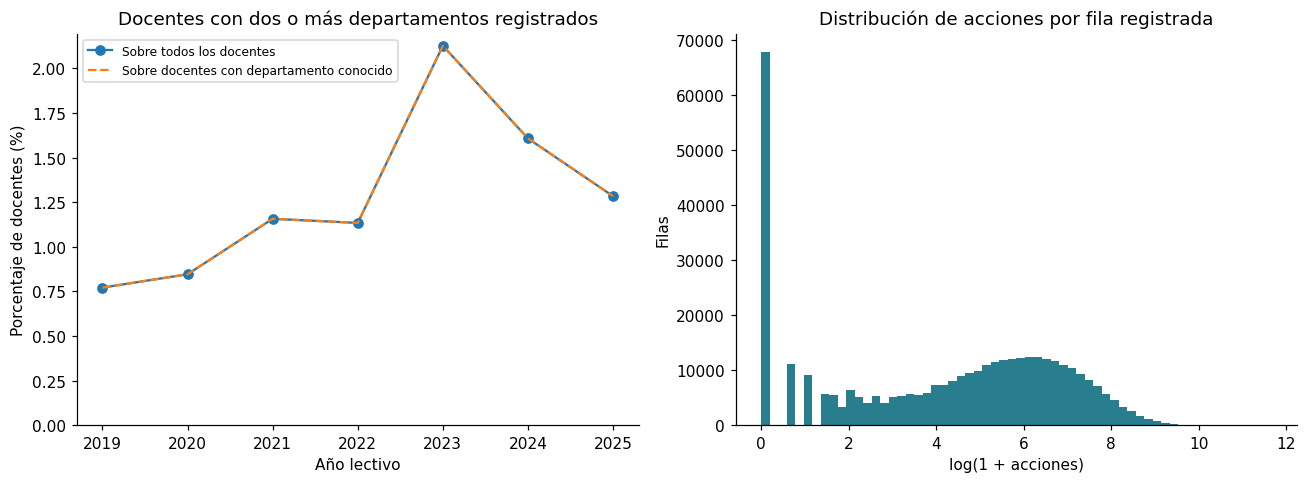

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(tabla_anual.index, tabla_anual["porcentaje_sobre_total"], marker="o", label="Sobre todos los docentes")
axes[0].plot(tabla_anual.index, tabla_anual["porcentaje_sobre_conocidos"], linestyle="--", label="Sobre docentes con departamento conocido")
axes[0].set(title="Docentes con dos o más departamentos registrados", xlabel="Año lectivo", ylabel="Porcentaje de docentes (%)", ylim=(0, None))
axes[0].legend(fontsize=8)
axes[1].hist(np.log1p(df_limpio["acciones"]), bins=60, color="#287D8E")
axes[1].set(title="Distribución de acciones por fila registrada", xlabel="log(1 + acciones)", ylabel="Filas")
fig.tight_layout()
plt.show()
plt.close(fig)

### Decisiones de cierre y exportación

**67 filas de `Sexo` completadas desde valores consistentes del mismo ID; 413 `Sin Dato` restantes y los 39 `Sin Dato` de `Departamento` conservados**. Se conservan las 379.153 filas, los ceros, los máximos y las discrepancias.

Para análisis por departamento o sexo, explicitar población elegible y faltantes. Para actividad, no sumar entre subsistemas; construir después una tabla persona–año y resolver su excepción antes de elegir un valor. No hay pruebas inferenciales ni modelos en este EDA.

In [70]:
assert len(df_limpio) == filas_docentes_originales == 379153
assert df_limpio[ID].nunique() == ids_docentes_originales == 74929
assert df_limpio["Sexo"].eq("Sin Dato").sum() == 413
assert df_limpio[DEPT].eq("Sin Dato").sum() == 39
assert df_limpio.columns.tolist() == df_d.columns.tolist()
assert df_d.drop(columns="Sexo").equals(df_limpio.drop(columns="Sexo"))
assert df_d["Sexo"].ne(df_limpio["Sexo"]).sum() == 67
salida_docentes = RAIZ / "Recursos/Dataset docentes limpio/docentes_limpio.parquet"
manifest_d = exportar_verificado(df_limpio, salida_docentes, ruta_docentes, "docentes", [
    "Unificación comentarios/acciones con combine_first, sin solapamientos",
    "strip en Sexo, Subsistema y Departamento",
    "67 faltantes Sexo completados para 62 IDs con valor conocido único; restantes conservados",
    "Sin eliminación de filas, imputación de Departamento, recorte de extremos ni reemplazo de ceros",
])
assert sha256(ruta_docentes) == huella_docentes_antes
display(pd.Series({k: manifest_d[k] for k in ["filas", "columnas", "personas_distintas", "relectura_identica"]}))
print("Salida verificada:", salida_docentes.relative_to(RAIZ))

filas                 379153
columnas                  12
personas_distintas     74929
relectura_identica      True
dtype: object

Salida verificada: Recursos\Dataset docentes limpio\docentes_limpio.parquet


## Nota de transparencia sobre uso de IA en la siguiente celda:

La idea de este repositorio es experimentar y aprender, y en este caso me pregunte: ¿Se podría automatizar la demostración en formato markdown? Es decir, ¿podríamos a traves de variables formatear una celda de markdown según resultados anteriores sin tener que modifcarla constantemente?

Intenté varias veces hacerlo a mano pero siempre tenía errores, por ello utilicé GPT Codex para crear la siguiente celda y aprender a hacerlo en un futuro. **Resulta que sí es posible formatear automáticamente una celda Markdown**

In [71]:
display(Markdown(f"""### Conclusión del EDA de docentes

- **Resultado:** {len(df_limpio):,} filas y {df_limpio[ID].nunique():,} docentes distintos. La clave docente–año–subsistema tiene {int(df_limpio.duplicated(KEY + ['Subsistema']).sum())} fila extra; se conserva.
- **Departamentos:** {len(revision6):,} casos docente–año representan {revision6.index.get_level_values(ID).nunique():,} personas distintas con al menos dos departamentos conocidos en algún año. El porcentaje anual observado tiene máximo en {int(tabla_anual['porcentaje_sobre_total'].idxmax())}; no prueba traslados ni causa alguna.
- **Actividad:** máximo registrado de {df_limpio['acciones'].max():,.0f} acciones; {int(ceros_crea.ne(ceros_acciones).sum()):,} filas difieren en el estado cero entre días CREA y acciones. Ambas observaciones se conservan.
- **Calidad:** discrepancias entre filas hermanas por métrica en `repeticion_metricas.csv`; no se presume que todos los registros son copias idénticas.
- **Estado:** diagnóstico y limpieza conservadora completados; Parquet releído e idéntico. Preguntas externas (definiciones recientes, ceros, máximo y excepción) quedan abiertas como limitaciones, no como errores que deban borrarse.

**Preguntas respondibles después:** cobertura y actividad registrada por año, diferencias descriptivas por subsistema y patrones de faltantes, con una unidad persona–año validada y sin atribuir efectos educativos o causales a estas métricas.
"""))

### Conclusión del EDA de docentes

- **Resultado:** 379,153 filas y 74,929 docentes distintos. La clave docente–año–subsistema tiene 1 fila extra; se conserva.
- **Departamentos:** 4,404 casos docente–año representan 2,826 personas distintas con al menos dos departamentos conocidos en algún año. El porcentaje anual observado tiene máximo en 2023; no prueba traslados ni causa alguna.
- **Actividad:** máximo registrado de 116,678 acciones; 721 filas difieren en el estado cero entre días CREA y acciones. Ambas observaciones se conservan.
- **Calidad:** discrepancias entre filas hermanas por métrica en `repeticion_metricas.csv`; no se presume que todos los registros son copias idénticas.
- **Estado:** diagnóstico y limpieza conservadora completados; Parquet releído e idéntico. Preguntas externas (definiciones recientes, ceros, máximo y excepción) quedan abiertas como limitaciones, no como errores que deban borrarse.

**Preguntas respondibles después:** cobertura y actividad registrada por año, diferencias descriptivas por subsistema y patrones de faltantes, con una unidad persona–año validada y sin atribuir efectos educativos o causales a estas métricas.
